# P3: perfiles de estaciones MiBici

Exploración para la pregunta **P3 (clustering)**: agrupar las estaciones según *cómo* se usan a lo largo del día y la semana, para apoyar decisiones de redistribución, expansión y configuración.

- **Unidad:** estación.
- **Periodo:** 2025 completo (enero a diciembre), que corresponde al periodo de entrenamiento. 2026 queda fuera para no usar información posterior.
- **Fuente:** `data/processed/viajes_AAAA_MM.parquet`, generados por `python -m mi_bici.dataset ingest`.

Este notebook es solo exploratorio; la lógica final debe vivir en `mi_bici/features.py` y en el módulo de modelado.

## Análisis 1: ¿Cuántos viajes tiene una estación típica?

In [64]:
import pandas as pd

v = pd.read_parquet("../data/processed/viajes_2025_01.parquet")
v.columns  # qué columnas tienes

Index(['trip_id', 'started_at', 'ended_at', 'origin_station_id',
       'destination_station_id', 'duration_minutes', 'invalid_start',
       'invalid_end', 'negative_duration', 'zero_duration',
       'duplicate_trip_id'],
      dtype='str')

In [65]:
v["started_at"].dt.hour.value_counts().sort_index()  # viajes por hora

started_at
0      2006
5      2715
6      9596
7     19540
8     29283
9     20453
10    17723
11    18274
12    19819
13    23039
14    25851
15    25836
16    24359
17    30111
18    38182
19    27383
20    19277
21    14546
22     8132
23     4059
Name: count, dtype: int64

In [66]:
v.groupby("origin_station_id").size()[:20]  # cuántos viajes tiene cada estación

origin_station_id
10     1337
100     324
101     135
102    1213
103     528
105     522
106     590
107     243
108    1115
11     5314
110    1772
111     477
112     462
115     612
117     671
118     630
119     248
12     2073
120     325
125     462
dtype: int64

In [67]:
import matplotlib.pyplot as plt
import pandas as pd

cols = [
    "started_at",
    "ended_at",
    "origin_station_id",
    "destination_station_id",
    "duration_minutes",
    "invalid_start",
    "invalid_end",
    "negative_duration",
    "zero_duration",
]
meses = pd.period_range("2025-01", "2025-12", freq="M").strftime("%Y_%m")
v = pd.concat(
    [pd.read_parquet(f"../data/processed/viajes_{m}.parquet", columns=cols) for m in meses],
    ignore_index=True,
)
print(len(v))
v[:5]

4532032


,started_at,ended_at,origin_station_id,destination_station_id,duration_minutes,invalid_start,invalid_end,negative_duration,zero_duration
0,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,10.750000,False,False,False,False
1,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,10.933333,False,False,False,False
2,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,9.933333,False,False,False,False
3,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,9.916667,False,False,False,False
4,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,9.300000,False,False,False,False


count      371.000000
mean     12215.719677
std      11430.336906
min        122.000000
25%       4614.000000
50%       8880.000000
75%      16312.000000
max      86834.000000
dtype: float64
50 0 estaciones por debajo
100 0 estaciones por debajo
200 1 estaciones por debajo
500 2 estaciones por debajo
1000 3 estaciones por debajo


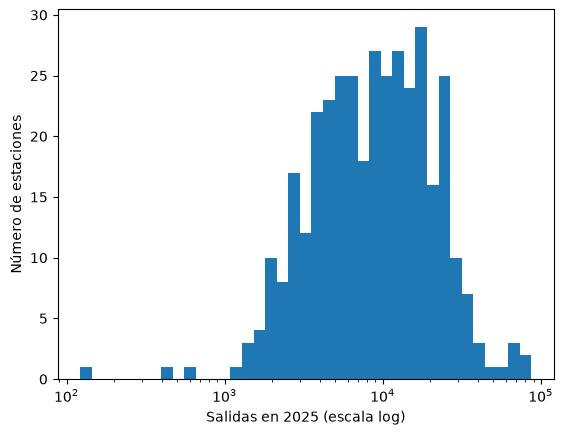

In [68]:
import numpy as np

por_estacion = v.groupby("origin_station_id").size().sort_values()
print(por_estacion.describe())
bins = np.geomspace(por_estacion.min(), por_estacion.max(), 40)
por_estacion.plot.hist(bins=bins, logx=True)
plt.xlabel("Salidas en 2025 (escala log)")
plt.ylabel("Número de estaciones")
for minimo in [50, 100, 200, 500, 1000]:
    print(minimo, (por_estacion < minimo).sum(), "estaciones por debajo")

In [69]:
bajas = por_estacion[por_estacion < 1000].index
v[v["origin_station_id"].isin(bajas)].groupby(
    ["origin_station_id", v["started_at"].dt.to_period("M")]
).size().unstack(fill_value=0)

started_at,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-10,2025-11,2025-12
origin_station_id,,,,,,,,,
240,132,118,131,105,97,14,0,0,0
401,0,0,0,0,0,0,122,165,146
402,0,0,0,0,0,0,0,0,122


▎ Las tres estaciones con menos de 1,000 salidas en 2025 no son errores, sino estaciones con actividad parcial: la 240 dejó de operar en junio de 2025 y la 401 y la 402 abrieron en octubre y diciembre. Se excluyen porque su perfil no cubre el periodo de entrenamiento completo. Las estaciones 401 y 402 (junto con la 405 y la 407 en 2026) indican una expansión reciente del sistema.

## Análisis 2: ¿Cuántos viajes vienen marcados?

In [70]:
banderas = ["invalid_start", "invalid_end", "negative_duration", "zero_duration"]
print(v[banderas].sum())
cualquiera = v[banderas].any(axis=1)
print(f"{cualquiera.sum():,} viajes marcados ({cualquiera.mean():.2%})")

invalid_start           0
invalid_end             0
negative_duration       0
zero_duration        2780
dtype: int64
2,780 viajes marcados (0.06%)


In [71]:
# ¿Se concentran en algunas estaciones?
ceros = v.loc[v["zero_duration"], "origin_station_id"].value_counts()
tasa = (ceros / por_estacion).dropna().sort_values(ascending=False)
tasa.head(10).map("{:.2%}".format)

origin_station_id
220    0.24%
308    0.23%
287    0.23%
336    0.23%
224    0.22%
316    0.17%
394    0.17%
329    0.16%
343    0.15%
139    0.15%
dtype: str

In [72]:
v.loc[v["zero_duration"], "started_at"].dt.to_period("M").value_counts().sort_index()

started_at
2025-01    205
2025-02    194
2025-03    216
2025-04    185
2025-05    189
2025-06    278
2025-07    253
2025-08    275
2025-09    228
2025-10    225
2025-11    214
2025-12    318
Freq: M, Name: count, dtype: int64

**Conclusión del análisis 2**
- **2,780 viajes marcados (0.06%)**, todos con **duración cero**. No hay fechas
  inválidas ni duraciones negativas.
- No se concentran en ninguna estación: la tasa más alta es **0.24%** de sus salidas
  (estación 220). La estación 51 tiene más duraciones cero en número absoluto (60),
  pero porque tiene un volumen muy alto; su tasa es menor a 0.15%.
- Tampoco se concentran en el tiempo: entre **185 y 318 por mes** a lo largo de 2025,
  sin picos anormales.
- **Decisión:** se descartan antes de calcular los perfiles porque no representan
  uso real (son errores de anclaje). Por su volumen y su distribución uniforme, no
  afectan los resultados. En cambio, febrero de 2026 tiene 1,863 duraciones cero, un
  pico anormal que queda en el periodo de prueba y que hay que considerar al evaluar.

## Análisis 3: ¿Cómo se ve el patrón por hora de estaciones distintas?

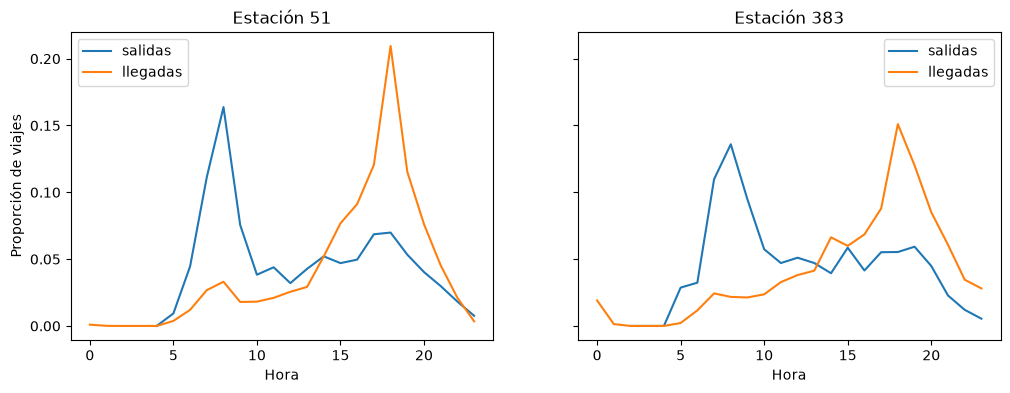

In [73]:
# Empieza por la estación más usada y por una de uso medio:
mas_usada = por_estacion.index[-1]
media = por_estacion.index[len(por_estacion) // 2]
entre_semana = v[(v["started_at"].dt.dayofweek < 5) & ~v["zero_duration"]]


def patron(datos, estacion):
    salidas = datos.loc[datos["origin_station_id"] == estacion, "started_at"].dt.hour
    llegadas = datos.loc[datos["destination_station_id"] == estacion, "ended_at"].dt.hour
    return pd.DataFrame(
        {
            "salidas": salidas.value_counts(normalize=True).sort_index(),
            "llegadas": llegadas.value_counts(normalize=True).sort_index(),
        }
    ).reindex(range(24), fill_value=0)


fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, est in zip(axes, [mas_usada, media]):
    patron(entre_semana, est).plot(ax=ax, title=f"Estación {est}")
    ax.set_xlabel("Hora")
    ax.set_ylabel("Proporción de viajes")

# Prueba con 4 o 5 estaciones más, cambiando el índice o eligiendo IDs que conozcas. Si ves estos tipos distintos, confirma que las
# proporciones por franja horaria son buenas variables para agrupar. Si todas se vieran iguales, habría que buscar otras.

# También vale la pena repetirlo con fin de semana (dayofweek >= 5) para ver si cambia el patrón. Eso justifica incluir la variable weekend_share.

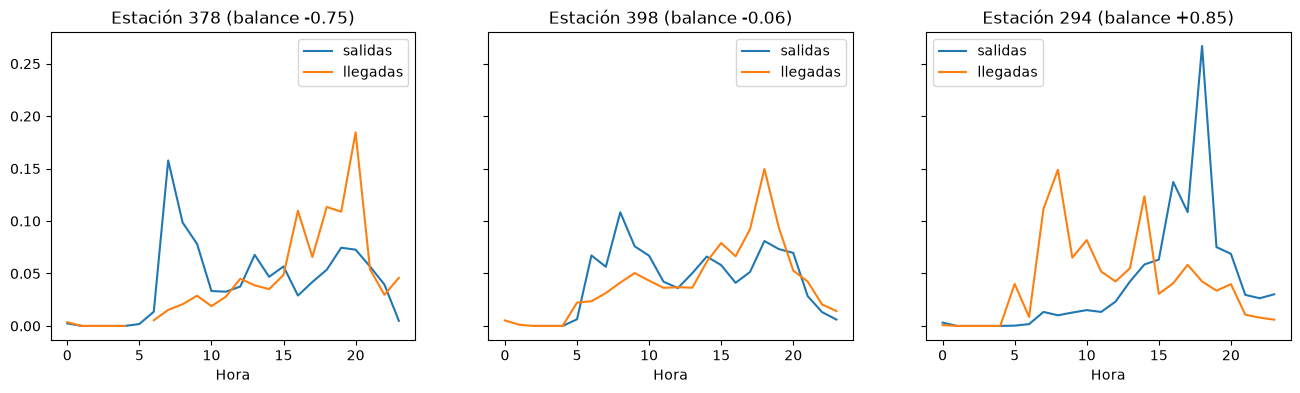

In [74]:
manana = entre_semana[entre_semana["started_at"].dt.hour.between(6, 9)]
sal = manana.groupby("origin_station_id").size()
lle = manana.groupby("destination_station_id").size()
balance = ((lle - sal) / (lle + sal)).dropna().sort_values()

ejemplos = [balance.index[0], balance.index[len(balance) // 2], balance.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, est in zip(axes, ejemplos):
    patron(entre_semana, est).plot(ax=ax, title=f"Estación {est} (balance {balance[est]:+.2f})")
    ax.set_xlabel("Hora")

# - balance.index[0], el más negativo, pierde bicis en la mañana. Se espera que sea residencial.
# - balance.index[-1], el más positivo, gana bicis en la mañana. Se espera que sea destino de trabajo o escuela.
# - El del medio debería verse equilibrado o mixto.

<Axes: title={'center': '294: fin de semana'}>

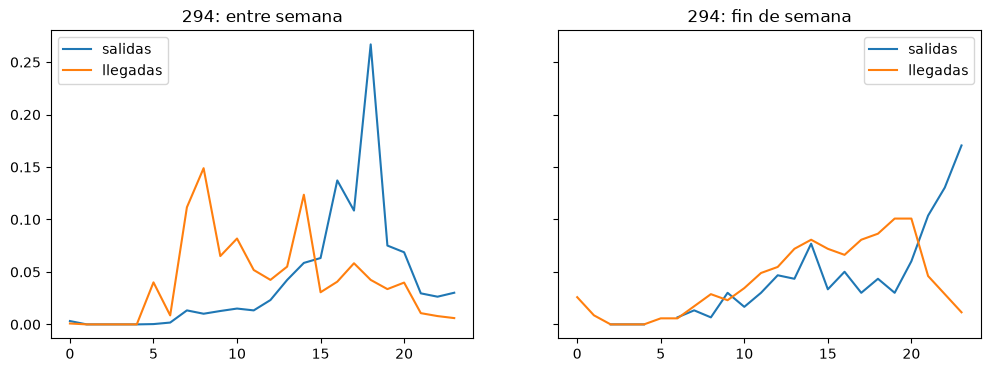

In [75]:
fin_semana = v[(v["started_at"].dt.dayofweek >= 5) & ~v["zero_duration"]]
est = ejemplos[-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
patron(entre_semana, est).plot(ax=axes[0], title=f"{est}: entre semana")
patron(fin_semana, est).plot(ax=axes[1], title=f"{est}: fin de semana")

**Conclusión del análisis 3**

- Hay al menos tres patrones distintos entre semana:
  - **Origen residencial** (estación 378, balance AM −0.75): pico de salidas a las 7 h y de llegadas a las 20 h.
  - **Mixta** (estación 398, balance AM −0.06): dos picos suaves de salidas y llegadas, sin que domine ninguno.
  - **Destino laboral** (estación 294, balance AM +0.85): pico de llegadas a las 8 h y de salidas a las 18 h.
- Coinciden con lo esperado: el balance de la hora pico de la mañana separa orígenes de destinos.
- En fin de semana el patrón de la 294 cambia por completo: desaparecen los picos de commuting y la actividad se reparte entre las 10 y las 22 h.
- **Decisión:** describir cada estación con el balance de las horas pico (AM y PM) calculado solo entre semana, y con la proporción de viajes en fin de semana.
- Las curvas están normalizadas a su propio total: muestran *cuándo* ocurre la actividad, no *cuánta*. El fin de semana tiene menos viajes, por lo que sus curvas son más ruidosas.

## Análisis 4: variables de perfil por estación

Se excluyen las duraciones cero (análisis 2) y las tres estaciones con actividad parcial (análisis 1). Los balances se calculan solo con días laborales:

- `balance_am` / `balance_pm`: (llegadas − salidas) / total en 6–9 h y 17–20 h. Positivo = destino, negativo = origen.
- `share_am` / `share_pm`: proporción de las salidas que ocurren en cada pico.
- `share_fin_semana`: proporción de las salidas que ocurren en sábado o domingo.
- `log_viajes_dia`: volumen, como log(1 + salidas por día).

In [76]:
base = v[~v["zero_duration"] & ~v["origin_station_id"].isin(bajas)]
es_laboral = base["started_at"].dt.dayofweek < 5


def balance(datos, horas):
    """(llegadas - salidas) / total en una franja: + destino, - origen."""
    sal = datos[datos["started_at"].dt.hour.isin(horas)].groupby("origin_station_id").size()
    lle = datos[datos["ended_at"].dt.hour.isin(horas)].groupby("destination_station_id").size()
    sal, lle = sal.align(lle, fill_value=0)
    return (lle - sal) / (lle + sal)


laboral = base[es_laboral]
salidas = base.groupby("origin_station_id").size()

perfil = pd.DataFrame(
    {
        "balance_am": balance(laboral, range(6, 10)),  # 378 ≈ -0.75, 294 ≈ +0.85
        "balance_pm": balance(laboral, range(17, 21)),  # se espera el signo contrario al AM
        "share_am": laboral.groupby("origin_station_id")["started_at"].apply(
            lambda s: s.dt.hour.between(6, 9).mean()
        ),
        "share_pm": laboral.groupby("origin_station_id")["started_at"].apply(
            lambda s: s.dt.hour.between(17, 20).mean()
        ),
        "share_fin_semana": base[~es_laboral].groupby("origin_station_id").size() / salidas,
        "log_viajes_dia": np.log1p(salidas / 365),
    }
).dropna()

perfil.describe()

,balance_am,balance_pm,share_am,share_pm,share_fin_semana,log_viajes_dia
count,368.000000,368.000000,368.000000,368.000000,368.000000,368.000000
mean,-0.066545,-0.010876,0.249172,0.307794,0.206829,3.232069
std,0.325988,0.257156,0.091471,0.076556,0.048479,0.796324
min,-0.757387,-0.717940,0.038004,0.134256,0.074341,1.444175
25%,-0.290176,-0.204190,0.181714,0.252413,0.179917,2.626057
50%,-0.073427,0.006369,0.241257,0.297175,0.201774,3.235342
75%,0.176783,0.156406,0.316055,0.356528,0.225930,3.826361
max,0.845062,0.673092,0.519366,0.613848,0.513729,5.475362


,balance_am,balance_pm,share_am,share_pm,share_fin_semana,log_viajes_dia
origin_station_id,,,,,,
369,-0.353081,0.292553,0.374918,0.174655,0.513729,2.259763
221,-0.598952,-0.291517,0.243513,0.431537,0.440973,2.586012
386,-0.506763,0.311103,0.356975,0.194189,0.432468,3.161131
46,0.481312,-0.365463,0.088856,0.408504,0.368011,3.814365
334,-0.252708,0.051628,0.277971,0.318825,0.358073,2.832246


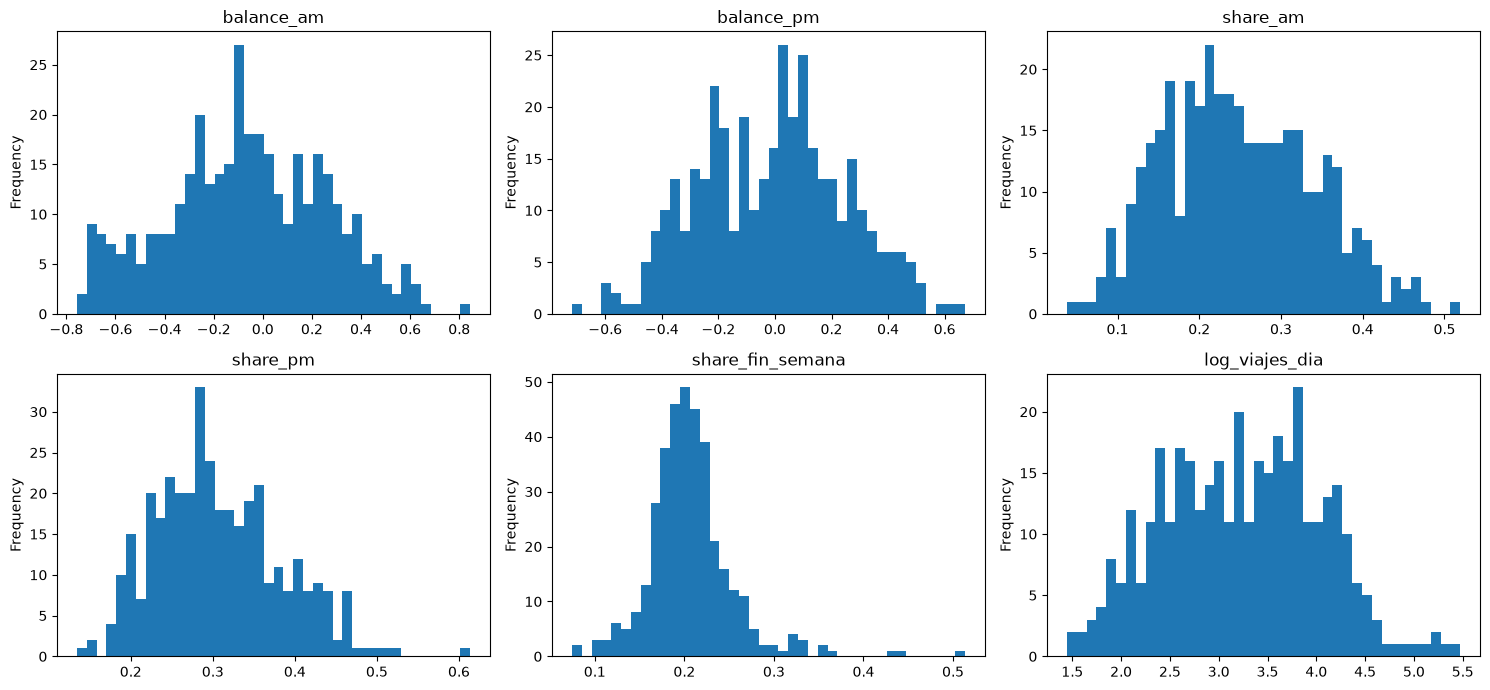

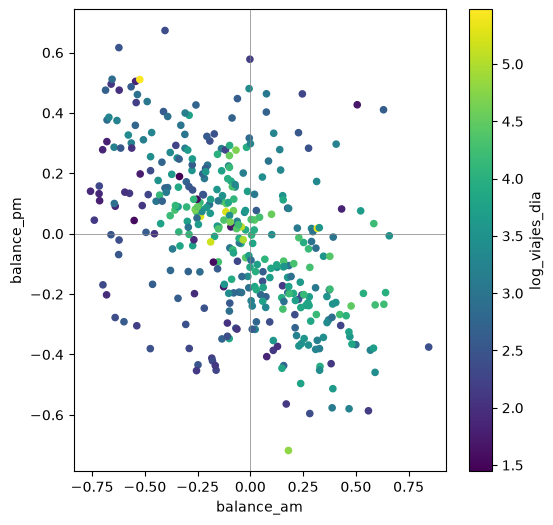

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, perfil.columns):
    perfil[col].plot.hist(bins=40, ax=ax, title=col)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(6, 6))
perfil.plot.scatter("balance_am", "balance_pm", c="log_viajes_dia", cmap="viridis", ax=ax)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)

perfil.sort_values("share_fin_semana", ascending=False).head(5)

**Conclusión del análisis 4**

- **368 estaciones** con perfil completo.
- **Redundancia:** `share_am` tiene correlación −0.80 con `balance_am` y `share_pm` −0.74 con `balance_pm`. Se conservan los balances porque, además de la intensidad, indican la dirección del flujo (origen o destino).
- `balance_am` y `balance_pm` solo tienen correlación −0.51: la tarde aporta información propia.
- `share_fin_semana` y `log_viajes_dia` son casi independientes de las demás (|corr| ≤ 0.31).
- **Distribuciones:** todas tienen una sola moda. Los perfiles forman un continuo, no grupos naturales bien separados, así que se espera una silhouette modesta.
- `share_fin_semana` está muy concentrada (IQR 0.18–0.23) con una cola de pocas estaciones arriba de 0.30. Sin tratamiento, esas estaciones dominarían al estandarizar.
- **Scatter:** diagonal negativa (quien pierde bicis en la mañana las recupera en la tarde). Las estaciones de mayor volumen se concentran en el centro y en la zona de destinos. El cuadrante inferior izquierdo agrupa estaciones que pierden bicis en ambos picos, un perfil relevante para la redistribución.

In [78]:
estaciones = pd.read_parquet("../data/processed/estaciones.parquet")
top = perfil.sort_values("share_fin_semana", ascending=False).head(5)
top.join(estaciones.set_index("station_id")[["station_name"]])

,balance_am,balance_pm,share_am,share_pm,share_fin_semana,log_viajes_dia,station_name
origin_station_id,,,,,,,
369,-0.353081,0.292553,0.374918,0.174655,0.513729,2.259763,(GDL-262) Av. Gigantes / C. Aquiles Serdán
221,-0.598952,-0.291517,0.243513,0.431537,0.440973,2.586012,(GDL-154) C. Capuchinas / Av. Las Rosas
386,-0.506763,0.311103,0.356975,0.194189,0.432468,3.161131,(GDL-254) Porfirio Díaz/Francisco Javier Mina
46,0.481312,-0.365463,0.088856,0.408504,0.368011,3.814365,(GDL-044) C. Gral. San Martín /Av. Vallarta
334,-0.252708,0.051628,0.277971,0.318825,0.358073,2.832246,"(GDL-261) C. Jarauta, Javier Mina"


Las cinco estaciones con más uso en fin de semana (36 % a 51 % de sus salidas) tienen volumen suficiente (más de 8 salidas al día), así que no son ruido. Cuatro de ellas son orígenes en la mañana (`balance_am` negativo). Pendiente: ubicarlas en el mapa para confirmar si están cerca de parques o zonas de ocio.

## Análisis 5: clustering con K-Means

Ajustes antes de agrupar:

- `balance_dia`: balance de todo el día laboral, para distinguir estaciones que pierden o acumulan bicis de forma sistemática.
- `share_fin_semana` se recorta al percentil 99 para que la cola no forme clusters de una o dos estaciones.

In [79]:
perfil["balance_dia"] = balance(laboral, range(24)).reindex(perfil.index)
p99 = perfil["share_fin_semana"].quantile(0.99)
print(
    f"Recorte de share_fin_semana en {p99:.3f}: {(perfil['share_fin_semana'] > p99).sum()} estaciones"
)
perfil["share_fin_semana"] = perfil["share_fin_semana"].clip(upper=p99)

Recorte de share_fin_semana en 0.361: 4 estaciones


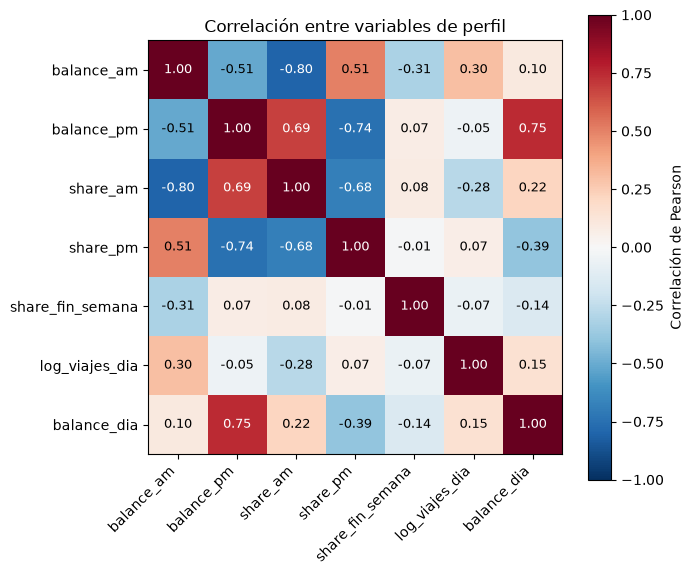

In [80]:
corr = perfil.drop(columns="cluster", errors="ignore").corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        valor = corr.iloc[i, j]
        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color="white" if abs(valor) > 0.6 else "black",
            fontsize=9,
        )
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre variables de perfil")
plt.tight_layout()

In [81]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42  # temporal: debe venir de RANDOM_STATE en mi_bici/config.py

conjuntos = {
    "am_pm": ["balance_am", "balance_pm", "share_fin_semana"],
    "am_dia": ["balance_am", "balance_dia", "share_fin_semana"],
    "am_pm_vol": ["balance_am", "balance_pm", "share_fin_semana", "log_viajes_dia"],
    "am_dia_vol": ["balance_am", "balance_dia", "share_fin_semana", "log_viajes_dia"],
}

resultados = []
for nombre, cols in conjuntos.items():
    X = StandardScaler().fit_transform(perfil[cols])
    for k in range(2, 9):
        etiquetas = [
            KMeans(n_clusters=k, n_init=10, random_state=SEED + i).fit_predict(X) for i in range(5)
        ]
        resultados.append(
            {
                "conjunto": nombre,
                "k": k,
                "silhouette": silhouette_score(X, etiquetas[0]),
                "estabilidad_ari": np.mean(
                    [adjusted_rand_score(etiquetas[0], e) for e in etiquetas[1:]]
                ),
                "tam_min": np.bincount(etiquetas[0]).min(),
            }
        )

resultados = pd.DataFrame(resultados)
for metrica in ["silhouette", "estabilidad_ari", "tam_min"]:
    print(metrica)
    print(resultados.pivot(index="k", columns="conjunto", values=metrica).round(3), end="\n\n")

silhouette
conjunto  am_dia  am_dia_vol  am_pm  am_pm_vol
k                                             
2          0.269       0.264  0.340      0.271
3          0.270       0.224  0.357      0.251
4          0.291       0.239  0.273      0.266
5          0.297       0.249  0.261      0.270
6          0.282       0.247  0.242      0.240
7          0.258       0.228  0.243      0.248
8          0.270       0.253  0.248      0.252

estabilidad_ari
conjunto  am_dia  am_dia_vol  am_pm  am_pm_vol
k                                             
2          1.000       1.000  1.000      0.986
3          0.987       0.835  1.000      1.000
4          0.907       0.962  1.000      0.975
5          0.954       0.822  0.873      0.979
6          0.744       0.962  0.643      0.700
7          0.798       0.793  0.586      0.929
8          0.856       0.691  0.702      0.897

tam_min
conjunto  am_dia  am_dia_vol  am_pm  am_pm_vol
k                                             
2            183       

**Selección del modelo**

- `balance_dia` tiene correlación 0.75 con `balance_pm`: casi todo el desbalance diario se explica por la tarde, así que no se usan las dos a la vez.
- **Agregar el volumen empeora la silhouette** en todos los casos (por ejemplo, de 0.357 a 0.251 con k = 3): los clusters terminarían separando estaciones muy usadas de poco usadas en lugar de perfiles de uso. El volumen se usa después solo para describir cada cluster.
- **Modelo elegido:** `am_pm` con **k = 3**. Tiene la mejor silhouette (0.357), es totalmente estable entre semillas (ARI = 1.00) y el cluster más pequeño tiene 53 estaciones.
- Alternativa: k = 4 con el mismo conjunto también es estable (ARI = 1.00), pero baja a una silhouette de 0.273. Divide el perfil residencial en uno muy marcado y otro mixto de alto volumen en el centro.

,estaciones,balance_am,balance_pm,balance_dia,share_fin_semana,viajes_dia_mediana
cluster,,,,,,
0,178,-0.280,0.186,0.026,0.206,22.920
1,137,0.205,-0.205,-0.056,0.177,31.153
2,53,-0.051,-0.168,-0.110,0.279,15.353


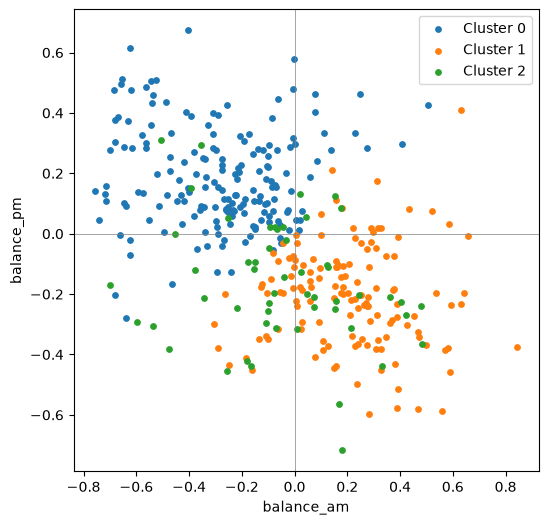

In [82]:
cols = conjuntos["am_pm"]
X = StandardScaler().fit_transform(perfil[cols])
perfil["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X)

resumen = perfil.groupby("cluster").agg(
    estaciones=("balance_am", "size"),
    balance_am=("balance_am", "mean"),
    balance_pm=("balance_pm", "mean"),
    balance_dia=("balance_dia", "mean"),
    share_fin_semana=("share_fin_semana", "mean"),
    viajes_dia_mediana=("log_viajes_dia", lambda s: np.expm1(s.median())),
)
display(resumen.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for c, datos in perfil.groupby("cluster"):
    ax.scatter(datos["balance_am"], datos["balance_pm"], s=15, label=f"Cluster {c}")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("balance_am")
ax.set_ylabel("balance_pm")
ax.legend()

**Conclusión del análisis 5: perfiles de estaciones**

| Cluster | Estaciones | Perfil | Rasgos |
|---|---:|---|---|
| 0 | 178 | **Residencial** | Pierde bicis en la mañana (`balance_am` −0.28) y las recupera en la tarde (+0.19). En el día queda equilibrada (+0.03). ~23 salidas/día. |
| 1 | 137 | **Destino laboral** | Gana bicis en la mañana (+0.21) y las pierde en la tarde (−0.21). Es el de mayor volumen, con ~31 salidas/día. |
| 2 | 53 | **Uso recreativo, pierde bicis** | Más uso en fin de semana (28 % frente a 18–21 %), pierde bicis en la tarde (−0.17) y en el día (−0.11). ~15 salidas/día. |

- Para la operación, el cluster 2 es el más relevante: es el único que pierde bicis de forma sistemática, por lo que necesita reabastecimiento aunque tenga menos volumen.
- Los clusters 0 y 1 se compensan entre sí a lo largo del día, de modo que la redistribución entre ellos se concentra en las horas pico.

**Limitaciones**

- Los perfiles forman un continuo, así que la silhouette es modesta (0.36). Los clusters son una segmentación útil y estable, no grupos naturales bien separados.
- Los perfiles usan solo 2025. Las estaciones abiertas después (401, 402, 405, 407) no tienen perfil.
- Las etiquetas numéricas de los clusters dependen de la semilla. Para comparar runs hay que usar los perfiles, no el número de cluster.